## Exercise project 2 : 

## Machine Predictive Maintenance Classification

## Data is : https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification


## Target variable :  1. Machine fails or not 





In [1]:
# usual imports in classic ML pipeline for Classification
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

# we need ADDITIONAL metrics ONLY for classification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

## Step 1: Loading and checking the data duplicates 

In [2]:
# load the data
df = pd.read_csv("predictive_maintenance.csv")

# let's study the data
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,No Failure


In [3]:
df.duplicated().sum()

np.int64(0)

## Step 2: Clean up  dataset: 
o Handle missing values 
o Handle potential big outliers 
o Remove duplicates
o Balance check 

In [4]:
df = df.drop(columns=['UDI', 'Product ID', 'Failure Type'])

type_mapping = {'L': 0, 'M': 1, 'H': 2}
df['Type'] = df['Type'].map(type_mapping)

print(df['Target'].value_counts())
df.info()

Target
0    9661
1     339
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Type                     10000 non-null  int64  
 1   Air temperature [K]      10000 non-null  float64
 2   Process temperature [K]  10000 non-null  float64
 3   Rotational speed [rpm]   10000 non-null  int64  
 4   Torque [Nm]              10000 non-null  float64
 5   Tool wear [min]          10000 non-null  int64  
 6   Target                   10000 non-null  int64  
dtypes: float64(3), int64(4)
memory usage: 547.0 KB


## The dataset has 10000 rows, 9661 are non failure while only 339 are failures 
## The dataset has no missing values and no duplicates 
## I  dropped the failure type becouse it is a target variable and also dropped the udi and product id becouse it does not help with the target prediction and the product id is diiferent in each row and it does not benefit me at all 

In [5]:
df['Temp diff'] = df['Process temperature [K]'] - df['Air temperature [K]']
df['Power'] = df['Torque [Nm]'] * df['Rotational speed [rpm]'] * 2 * 3.14159 / 60
df['Wear x torque'] = df['Tool wear [min]'] * df['Torque [Nm]']

## Data quality 

Missing value, correlation matrix , handling outliars

In [6]:
##  Missing values check
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
print('Missing values per column (only shown if > 0):')
print(missing[missing > 0])
print('\nMissing values percent (only shown if > 0):')
print(missing_pct[missing_pct > 0])
if missing.sum() == 0:
    print('\nAnalysis: No missing values detected. You can proceed without imputation.')
else:
    print(f'\nAnalysis: Detected missing values in {missing[missing>0].shape[0]} column(s). Consider imputation or removal depending on domain importance.')

Missing values per column (only shown if > 0):
Series([], dtype: int64)

Missing values percent (only shown if > 0):
Series([], dtype: float64)

Analysis: No missing values detected. You can proceed without imputation.


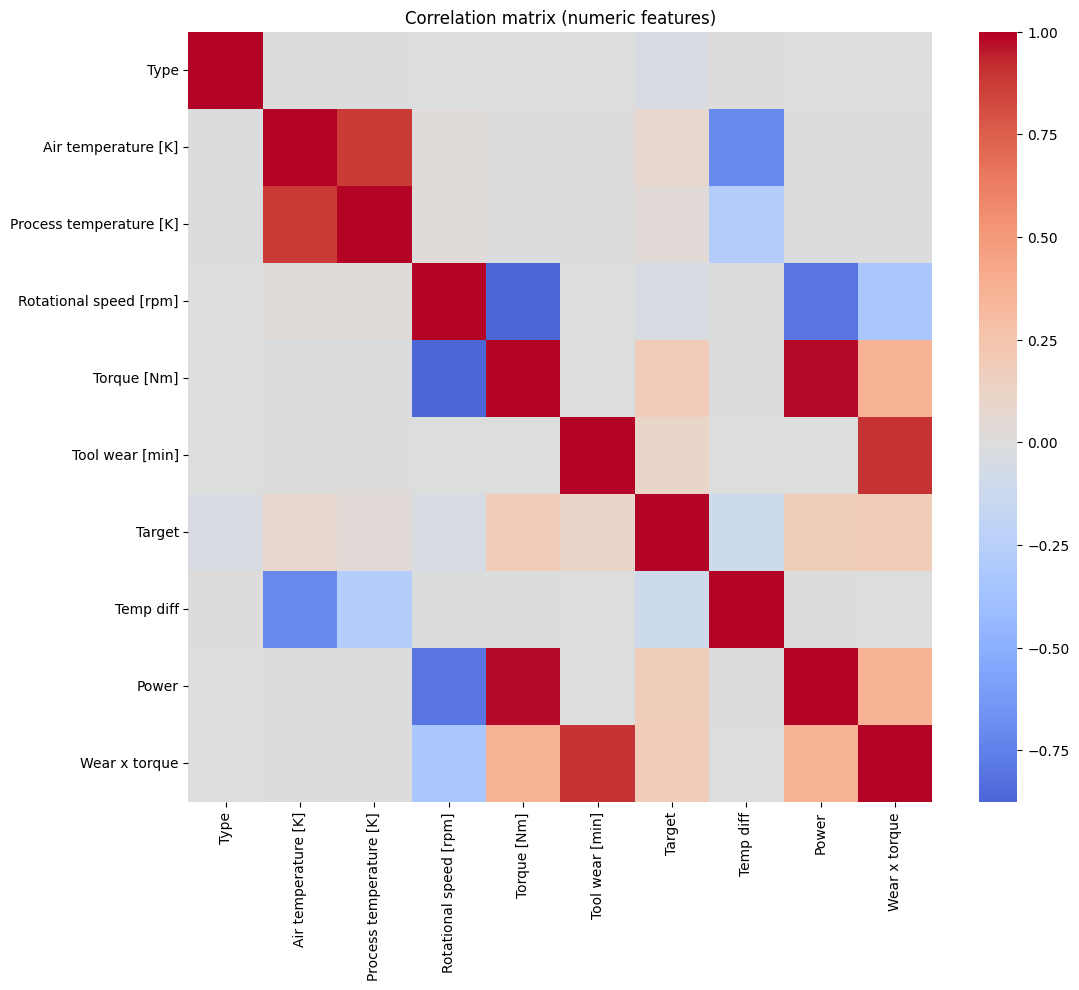


Top absolute correlations with Target:
Torque [Nm]                0.191321
Wear x torque              0.190427
Power                      0.176039
Temp diff                  0.111676
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Rotational speed [rpm]     0.044188
Type                       0.036715
Process temperature [K]    0.035946
Name: Target, dtype: float64

Analysis: Use features with higher correlation to Target as strong predictors but check multicollinearity if multiple features are highly correlated with each other.


In [7]:
## Correlation matrix (numeric features)
num = df.select_dtypes(include=[np.number])
corr = num.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, fmt='.2f')
plt.title('Correlation matrix (numeric features)')
plt.show()
# Show strongest correlations with the target
if 'Target' in corr.columns:
    target_corr = corr['Target'].drop('Target').abs().sort_values(ascending=False)
    print('\nTop absolute correlations with Target:')
    print(target_corr.head(10))
    print('\nAnalysis: Use features with higher correlation to Target as strong predictors but check multicollinearity if multiple features are highly correlated with each other.')
else:
    print('Target column not present in numeric subset; skipping target correlations.')

## Note of AI usage for the next cell from Code Assistance and cluade

In [8]:
# ---- Outlier detection using IQR method
num_cols = num.columns.tolist()
outlier_counts = {}
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_counts[col] = outliers.shape[0]
# show columns with outliers (sorted)
outlier_series = pd.Series(outlier_counts).sort_values(ascending=False)
print('Outlier counts per numeric column (IQR rule):')
print(outlier_series[outlier_series > 0])
print('\nAnalysis: Columns with many outliers may need capping, transformation (log, sqrt), or careful inspection for data entry errors.')
# show a few example rows that are extreme for the top column (if any)
if outlier_series.sum() > 0:
    top_col = outlier_series.index[0]
    Q1 = df[top_col].quantile(0.25)
    Q3 = df[top_col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(f'\nExample extreme rows for column: {top_col}')
    display(df[(df[top_col] < lower) | (df[top_col] > upper)].head())

Outlier counts per numeric column (IQR rule):
Rotational speed [rpm]    418
Target                    339
Torque [Nm]                69
Power                      60
Wear x torque              20
dtype: int64

Analysis: Columns with many outliers may need capping, transformation (log, sqrt), or careful inspection for data entry errors.

Example extreme rows for column: Rotational speed [rpm]


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Temp diff,Power,Wear x torque
14,0,298.6,309.2,2035,19.6,40,0,10.6,4176.848625,784.0
50,0,298.9,309.1,2861,4.6,143,1,10.2,1378.173645,657.8
70,1,298.9,309.0,1924,22.6,193,0,10.1,4553.462434,4361.8
101,0,298.8,308.8,1991,20.7,59,0,10.0,4315.884926,1221.3
155,2,298.4,308.2,1987,19.8,198,0,9.8,4119.943958,3920.4


In [9]:
# 4) Outlier decision: demonstrate capping (winsorization) vs removal
df_capped = df.copy()
before_counts = {}
after_counts = {}
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    before_counts[col] = df[(df[col] < lower) | (df[col] > upper)].shape[0]
    df_capped[col] = df_capped[col].clip(lower=lower, upper=upper)
    after_counts[col] = df_capped[(df_capped[col] < lower) | (df_capped[col] > upper)].shape[0]
print('Outlier counts before capping (IQR rule):')
print(pd.Series(before_counts).sort_values(ascending=False)[pd.Series(before_counts) > 0])
print('\nOutlier counts after capping (should be 0):')
print(pd.Series(after_counts).sort_values(ascending=False)[pd.Series(after_counts) > 0])
print('\nAnalysis: Capping replaces extreme values with threshold values, preserving row count. Alternatively, you can remove rows with extreme values using df = df[~condition], but be cautious if many rows are removed.')

Outlier counts before capping (IQR rule):
Rotational speed [rpm]    418
Target                    339
Torque [Nm]                69
Power                      60
Wear x torque              20
dtype: int64

Outlier counts after capping (should be 0):
Series([], dtype: int64)

Analysis: Capping replaces extreme values with threshold values, preserving row count. Alternatively, you can remove rows with extreme values using df = df[~condition], but be cautious if many rows are removed.


## You asked me to add the Balance check becouse it seems that the model has a high prediction but becouse it could not detect errors

Class counts:
Target
0    9661
1     339
Name: count, dtype: int64

Class percentages:
Target
0    96.61
1     3.39
Name: proportion, dtype: float64


C:\Users\omer_\AppData\Local\Temp\ipykernel_40696\1141027906.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='viridis')


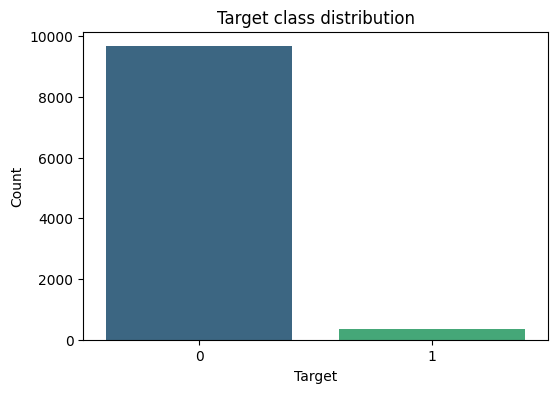


Analysis: If classes are heavily imbalanced (one class >> others), consider resampling techniques (SMOTE, undersampling) or class_weight adjustments in models.


In [10]:

if 'Target' in df.columns:
    counts = df['Target'].value_counts()
    pct = df['Target'].value_counts(normalize=True) * 100
    print('Class counts:')
    print(counts)
    print('\nClass percentages:')
    print(pct.round(2))
    plt.figure(figsize=(6,4))
    sns.barplot(x=counts.index, y=counts.values, palette='viridis')
    plt.xlabel('Target')
    plt.ylabel('Count')
    plt.title('Target class distribution')
    plt.show()
    print('\nAnalysis: If classes are heavily imbalanced (one class >> others), consider resampling techniques (SMOTE, undersampling) or class_weight adjustments in models.')
else:
    print('Target column not found in dataframe.')

## step 3: X/y and train/test -split

In [11]:
X = df.drop("Target", axis=1)
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(7000, 9) (3000, 9)
Target
0    6763
1     237
Name: count, dtype: int64
Target
0    2898
1     102
Name: count, dtype: int64


## Scaling the support variables

In [12]:
# Replace manual scaling with a ColumnTransformer + Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
# We'll build the preprocessor after we know X_train/X_test (they are DataFrames)
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
# Force 'Type' to be treated as categorical (even if encoded as numbers earlier)
cat_cols = []
if 'Type' in X.columns:
    if 'Type' in num_cols:
        num_cols.remove('Type')
    cat_cols.append('Type')
# Build preprocessor: scale numeric, one-hot encode categoricals
if len(cat_cols) > 0:
    preprocessor = ColumnTransformer(transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ], remainder='drop')
else:
    preprocessor = ColumnTransformer(transformers=[
        ('num', StandardScaler(), num_cols)
    ], remainder='drop')
print('Preprocessor ready. Numeric cols:', len(num_cols), 'Categorical cols:', len(cat_cols))

Preprocessor ready. Numeric cols: 8 Categorical cols: 1


## Step 4: Train the logistic regression model

In [13]:
# Build a pipeline with the preprocessor and logistic regression (handles class imbalance)
from sklearn.linear_model import LogisticRegression
model = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(class_weight={0:1, 1:10}, max_iter=1000))
])
# Fit the pipeline on the DataFrame splits (preprocessing happens inside)
model.fit(X_train, y_train)
print('Pipeline trained: preprocessor + LogisticRegression')

Pipeline trained: preprocessor + LogisticRegression


## Step 5: Classification error metrics

In [14]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

try:
    preds = predictions
except NameError:
    preds = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, preds), 4))
print("\nClassification report:\n", classification_report(y_test, preds))
print("\nConfusion matrix:\n", confusion_matrix(y_test, preds))

if hasattr(model, "predict_proba"):
    try:
        probs = model.predict_proba(X_test)
        if probs.shape[1] == 2:
            print("\nROC-AUC:", round(roc_auc_score(y_test, probs[:, 1]), 4))
        print("\nExample predicted probabilities (first 5 rows):")
        for i, p in enumerate(probs[:5], start=1):
            print(f" Row {i}:", np.round(p, 4))
    except Exception as e:
        print("Could not compute probabilities:", e)
else:
    print("\nModel has no predict_proba; cannot show probabilities or ROC-AUC.")

if 'new_machine_scaled' in globals():
    try:
        print("\nNew machine predicted probabilities:", np.round(model.predict_proba(new_machine_scaled)[0], 4))
    except Exception as e:
        print("Could not get new_machine probabilities:", e)
elif 'new_machine' in globals():
    try:
        print("\nNew machine predicted probabilities (unscaled):", np.round(model.predict_proba(new_machine)[0], 4))
    except Exception:
        pass

Accuracy: 0.936

Classification report:
               precision    recall  f1-score   support

           0       0.99      0.95      0.97      2898
           1       0.30      0.66      0.41       102

    accuracy                           0.94      3000
   macro avg       0.64      0.80      0.69      3000
weighted avg       0.96      0.94      0.95      3000


Confusion matrix:
 [[2741  157]
 [  35   67]]

ROC-AUC: 0.9199

Example predicted probabilities (first 5 rows):
 Row 1: [0.9951 0.0049]
 Row 2: [0.9951 0.0049]
 Row 3: [0.9443 0.0557]
 Row 4: [0.8764 0.1236]
 Row 5: [0.9657 0.0343]


In [15]:
predictions = model.predict(X_test)

In [16]:
print(classification_report(y_test, predictions))

# get overall accuracy of the model and print it
acc = accuracy_score(y_test, predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

              precision    recall  f1-score   support

           0       0.99      0.95      0.97      2898
           1       0.30      0.66      0.41       102

    accuracy                           0.94      3000
   macro avg       0.64      0.80      0.69      3000
weighted avg       0.96      0.94      0.95      3000


Model overall accuracy: 93.60%


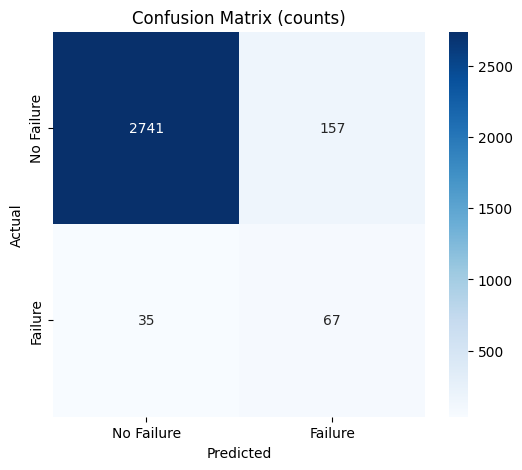

Confusion matrix (row-normalized percentages):
[[0.946 0.054]
 [0.343 0.657]]


In [17]:
# Confusion matrix with labels and counts
cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=['No Failure','Failure'], yticklabels=['No Failure','Failure'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (counts)')
plt.show()
# Print percentages for clarity
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, None]

print('Confusion matrix (row-normalized percentages):')
print(np.round(cm_pct, 3))


The model seems to predict 67 failure but failed to predict 35 of them 

##  Step 6 : Testing the accuracy 

In [18]:
# Step 6 (ROC-AUC) with safe handling
try:
    roc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print('ROC-AUC:', round(roc,4))
except Exception as e:
    print('Could not compute ROC-AUC:', e)

# Safe new_machine prediction using the trained pipeline (no manual scaling)
type_mapping = {'L':0,'M':1,'H':2}
new_machine = pd.DataFrame([{ 'Type': type_mapping['L'], 'Air temperature [K]': 298.5, 'Process temperature [K]': 308.1, 'Rotational speed [rpm]': 1551, 'Torque [Nm]': 40.0, 'Tool wear [min]': 180 }])
new_machine['Temp diff'] = new_machine['Process temperature [K]'] - new_machine['Air temperature [K]']
new_machine['Power'] = new_machine['Torque [Nm]'] * new_machine['Rotational speed [rpm]'] * 2 * 3.14159 / 60
new_machine['Wear x torque'] = new_machine['Tool wear [min]'] * new_machine['Torque [Nm]']
# Align columns with training data (fill missing with 0)
new_machine = new_machine.reindex(columns=X.columns, fill_value=0)
try:
    p = model.predict_proba(new_machine)[0]
    pred = model.predict(new_machine)[0]
    print('\nNew machine prediction:', pred)
    print('New machine probabilities:', np.round(p,4))
except Exception as e:
    print('Could not predict new_machine:', e)

ROC-AUC: 0.9199

New machine prediction: 0
New machine probabilities: [0.8704 0.1296]


## Step 7: Tester rows (low-risk and high-risk) and explanation

Below is a low-risk example and a high-risk example (worn tool, high torque, low speed, small temp diff) and show how probabilities change.

In [19]:
# Low-risk example (existing pattern) and a constructed high-risk example
low = pd.DataFrame([{
    'Type': 'L',
    'Air temperature [K]': 298.5,
    'Process temperature [K]': 308.1,
    'Rotational speed [rpm]': 1551,
    'Torque [Nm]': 40.0,
    'Tool wear [min]': 180,
}])
high = pd.DataFrame([{
    'Type': 'H',  
    'Air temperature [K]': 300.0,
    'Process temperature [K]': 301.0,  
    'Rotational speed [rpm]': 500,   
    'Torque [Nm]': 200.0,            
    'Tool wear [min]': 900,         
}])
# Create engineered features to match training preprocessing
for df_example in (low, high):
    df_example['Temp diff'] = df_example['Process temperature [K]'] - df_example['Air temperature [K]']
    df_example['Power'] = df_example['Torque [Nm]'] * df_example['Rotational speed [rpm]'] * 2 * 3.14159 / 60
    df_example['Wear x torque'] = df_example['Tool wear [min]'] * df_example['Torque [Nm]']
# Predict probabilities using the pipeline model
for name, ex in [('Low-risk', low), ('High-risk', high)]:
    try:
        p = model.predict_proba(ex)[0]
        print(f'{name} probabilities:', np.round(p,4))
    except Exception as e:
        print('Could not compute probabilities for', name, e)

Low-risk probabilities: [0.9022 0.0978]
High-risk probabilities: [0. 1.]


## Analysis for the testing
- `Type` was encoded as L/M/H mapped to 0/1/2. This is only justified if the categories are ordinal; otherwise OneHotEncoder is safer. In this notebook we used one-hot encoding inside the pipeline to avoid implying linear spacing.
- `class_weight={0:1,1:10}` increases the penalty for misclassifying failures (class 1) to handle imbalance; alternatives include resampling (SMOTE) or different class weights.
- Engineered features (`Temp diff`, `Power`, `Wear x torque`) were selected because they capture meaningful interactions: temperature difference indicates heating stress, `Power` relates to mechanical load, and `Wear x torque` couples wear with applied torque — all can increase failure risk.

##  using the model in practice

In [20]:
df.columns

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target',
       'Temp diff', 'Power', 'Wear x torque'],
      dtype='str')

## AI usage for the next cell from the code Assistance

## Printing the prediction of the failure and the propbabilty of it 

In [21]:
# Example new machine to predict
new_machine = pd.DataFrame([{
    "Type": "L",
    "Air temperature [K]": 298.5,
    "Process temperature [K]": 308.1,
    "Rotational speed [rpm]": 1551,
    "Torque [Nm]": 40.0,
    "Tool wear [min]": 180,
}])

# Create engineered features
new_machine['Temp diff'] = new_machine['Process temperature [K]'] - new_machine['Air temperature [K]']
new_machine['Power'] = new_machine['Torque [Nm]'] * new_machine['Rotational speed [rpm]'] * 2 * 3.14159 / 60
new_machine['Wear x torque'] = new_machine['Tool wear [min]'] * new_machine['Torque [Nm]']

# Keep same columns as training data
new_machine = new_machine.reindex(columns=X.columns, fill_value=0)

# Predict
pred = model.predict(new_machine)[0]
prob = model.predict_proba(new_machine)[0]

print("Prediction (0 = no failure, 1 = failure):", pred)
print("Probability of failure:", round(prob[1], 4))

Prediction (0 = no failure, 1 = failure): 0
Probability of failure: 0.0978


## Final step is my own analysis 
Goal: Predict whether a machine will fail using logistic regression on the Kaggle predictive maintenance dataset (10,000 rows, 9,661 non-failures and 339 failures).

Data: There were no missing values or duplicates. The dataset is heavily imbalanced, with only 3.4% failures. A model that always predicted “no failure” would be about 97% accurate while being useless, so accuracy alone is misleading here. To handle the imbalance, I used a stratified 70/30 split and gave failures 10x the weight in the model.

Features: Torque, wear × torque and power had the strongest link to failure. I added three features: temperature difference, power and wear × torque. These capture heat stress, mechanical load and wear under load.

Results on the test set (3,000 rows):

Metric	Value
Accuracy	93.6%
ROC-AUC	0.92
Failure recall	66% (67 of 102 failures caught)
Failure precision	30% (157 false alarms)

Interpretation: The model is good at ranking risk (ROC-AUC 0.92) and catches about two thirds of real failures. The cost is many false alarms, so only 30% of its failure warnings are correct. It still missed 35 failures. In maintenance, a missed failure is usually more expensive than an unnecessary inspection, so I accepted the false alarms.

Example predictions: A normal machine got a failure probability of about 10%, while a high-risk machine (heavily worn tool, high torque, low speed) got close to 100%. This shows the model responds sensibly to risky conditions.

Conclusion: Logistic regression is a reasonable baseline for this problem. To improve it, I would try tuning the decision threshold or testing a tree-based model such as Random Forest to cut false alarms while keeping recall high.

## I need to work more on my data optamization :)
